# EDA 01: train の1分子(inchikey14)の中身を見る

train には `molecule_id` が無いので、分子の単位は `inchikey14`(立体化学を除いた2D骨格)とする。
1分子に紐づく全スペクトル(ライブラリ・アダクト・衝突エネルギー違い)を可視化する。

- 対象分子は `TARGET_INCHIKEY14` で指定。`None` ならテストに最も近い `enveda-np-examples` から自動選択
- train.parquet(約3GB)は全件ロードせず、pyarrow の filter で必要な行だけ読む

In [1]:
try:
    import rdkit  # noqa: F401
except ImportError:
    %pip install -q rdkit

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw

DATA_DIR = Path("/kaggle/working/enveda-CASMI26-molecule-id-mass-spectra")
TRAIN_PATH = DATA_DIR / "train.parquet"

TARGET_INCHIKEY14 = None  # 例: "OIGNJSKKLXVSLS"。None なら自動選択

# テストに含まれるアダクト10種
TEST_ADDUCTS = [
    "[M+H]+", "[M+NH4]+", "[M-H2O+H]+", "[M-2H2O+H]+", "[M+Na]+", "[M+K]+",
    "[M-H]-", "[M-H2O-H]-", "[M+CH2O2-H]-", "[M+Cl]-",
]

# ライブラリごとの色(固定順)。テストに近い2つを先頭に置く
LIB_ORDER = [
    "enveda-np-examples", "enveda-180", "pluskal_ms2", "gnps", "riken",
    "massbank", "mona", "spectraverse", "msdial", "drug_plus", "masaryk",
]
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
LIB_COLOR = {lib: PALETTE[i] if i < len(PALETTE) else "#8a8984" for i, lib in enumerate(LIB_ORDER)}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

## 1. 対象分子の選択

train.parquet は `(ingest_lib, inchikey14)` 順に並んでおり、`enveda-np-examples` は最後の row group だけに入っている。
そこから250分子を取り、train全体での出現ライブラリ数・アダクト数を数える。
ライブラリ数が最大で、スペクトル数が多すぎない(300以下)分子のうち、アダクト数が最も多いものを選ぶ。

In [3]:
pf = pq.ParquetFile(TRAIN_PATH)
print(f"row groups: {pf.metadata.num_row_groups}, rows: {pf.metadata.num_rows:,}")

np_ex = pf.read_row_group(pf.metadata.num_row_groups - 1, columns=["ingest_lib", "inchikey14"]).to_pandas()
assert (np_ex["ingest_lib"] == "enveda-np-examples").all()
cand_keys = np_ex["inchikey14"].unique().tolist()

cand_meta = pq.read_table(
    TRAIN_PATH,
    columns=["inchikey14", "ingest_lib", "adduct"],
    filters=[("inchikey14", "in", cand_keys)],
).to_pandas()

cand_stats = (
    cand_meta.groupby("inchikey14")
    .agg(n_spectra=("adduct", "size"), n_libs=("ingest_lib", "nunique"), n_adducts=("adduct", "nunique"))
    .sort_values(["n_libs", "n_adducts", "n_spectra"], ascending=False)
)
display(cand_stats.describe().round(1))
display(cand_stats.head(10))

row groups: 21, rows: 2,539,608


,n_spectra,n_libs,n_adducts
count,250.0,250.0,250.0
mean,227.1,7.3,5.6
std,211.7,1.5,2.5
min,5.0,3.0,1.0
25%,91.2,7.0,4.0
50%,174.5,7.0,5.0
75%,309.8,8.0,7.0
max,1468.0,9.0,15.0


,n_spectra,n_libs,n_adducts
inchikey14,,,
OIGNJSKKLXVSLS,214,9,10
FBPFZTCFMRRESA,453,9,9
YGPSJZOEDVAXAB,386,9,9
JYGXADMDTFJGBT,366,9,9
CKLJMWTZIZZHCS,333,9,9
PCZOHLXUXFIOCF,318,9,9
WTDRDQBEARUVNC,304,9,9
ZFXYFBGIUFBOJW,581,9,8
CZMRCDWAGMRECN,185,9,8


In [4]:
if TARGET_INCHIKEY14 is None:
    pool = cand_stats[(cand_stats["n_libs"] == cand_stats["n_libs"].max()) & (cand_stats["n_spectra"] <= 300)]
    TARGET_INCHIKEY14 = pool.index[0]
print("TARGET_INCHIKEY14 =", TARGET_INCHIKEY14)

TARGET_INCHIKEY14 = OIGNJSKKLXVSLS


## 2. 対象分子の全スペクトルを読み込む

In [5]:
mol = pq.read_table(TRAIN_PATH, filters=[("inchikey14", "==", TARGET_INCHIKEY14)]).to_pandas()

mol["lib_rank"] = mol["ingest_lib"].map({lib: i for i, lib in enumerate(LIB_ORDER)})
mol["ce_first"] = mol["collision_energy_ev"].map(lambda x: x[0] if x is not None and len(x) else np.nan)
mol["in_test_adducts"] = mol["adduct"].isin(TEST_ADDUCTS)
mol = mol.sort_values(["lib_rank", "adduct", "ce_first"]).reset_index(drop=True)

print(f"{len(mol)} spectra, columns: {list(mol.columns)}")

214 spectra, columns: ['ingest_lib', 'normalized_smiles', 'inchikey', 'inchikey14', 'molecular_formula', 'ionization_mode', 'instrument_type', 'adduct', 'adduct_orig', 'precursor_mz', 'precursor_error_ppm', 'ms2_mzs', 'ms2_normalized_intensities', 'num_peaks', 'base_peak_intensity', 'collision_energy_ev', 'collision_energy_orig', 'collision_energy_orig_units', 'lib_rank', 'ce_first', 'in_test_adducts']


## 3. 構造とラベル情報

normalized_smiles の種類数: 1 (立体違いなどで複数になりうる)


,normalized_smiles,inchikey,molecular_formula
0,CC12C=CC(=O)C=C1CCC1C2C(O)CC2(C)C1CCC2(O)C(=O)CO,OIGNJSKKLXVSLS-UHFFFAOYSA-N,C21H28O5


monoisotopic mass: 360.1937


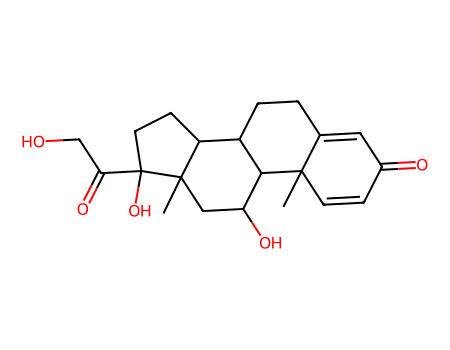

In [6]:
smiles_list = mol["normalized_smiles"].unique()
print("normalized_smiles の種類数:", len(smiles_list), "(立体違いなどで複数になりうる)")
display(mol[["normalized_smiles", "inchikey", "molecular_formula"]].drop_duplicates().reset_index(drop=True))

m = Chem.MolFromSmiles(smiles_list[0])
print("monoisotopic mass:", round(Descriptors.ExactMolWt(m), 4))
Draw.MolToImage(m, size=(450, 350))

## 4. メタデータ一覧

ライブラリ・アダクト・CE・装置などがスペクトルごとにどう違うかを見る。

In [7]:
META_COLS = [
    "ingest_lib", "adduct", "adduct_orig", "ionization_mode", "instrument_type",
    "collision_energy_ev", "collision_energy_orig", "collision_energy_orig_units",
    "precursor_mz", "precursor_error_ppm", "num_peaks", "base_peak_intensity",
]
with pd.option_context("display.max_rows", 30, "display.max_colwidth", 40):
    display(mol[META_COLS])

,ingest_lib,adduct,adduct_orig,ionization_mode,instrument_type,collision_energy_ev,collision_energy_orig,collision_energy_orig_units,precursor_mz,precursor_error_ppm,num_peaks,base_peak_intensity
0,enveda-np-examples,[M+CH2O2-H]-,[M+CHO2]-,negative,timsTOF,"[20.0, 50.0]",20;50,eV,405.19200,0.303925,427,511669.0
1,enveda-np-examples,[M+H]+,[M+H]+,positive,timsTOF,"[20.0, 50.0]",20;50,eV,361.20149,1.493773,906,202833.0
2,enveda-np-examples,[M+K]+,[M+K]+,positive,timsTOF,"[20.0, 50.0]",20;50,eV,399.15725,1.047443,38,2801.0
3,enveda-np-examples,[M+Na]+,[M+Na]+,positive,timsTOF,"[20.0, 50.0]",20;50,eV,383.18453,4.267685,48,122470.0
4,enveda-np-examples,[M-2H2O+H]+,[M-H3O2]+,positive,timsTOF,"[20.0, 50.0]",20;50,eV,325.18010,0.857753,40,1572.0
...,...,...,...,...,...,...,...,...,...,...,...,...
209,msdial,[M+H]+,[M+H]+,positive,LC-ESI-QTOF,[40.0],40 eV,eV,361.20100,1.518868,147,NaN
210,msdial,[M+H]+,[M+H]+,positive,LC-ESI-QTOF,[50.0],50 eV,eV,361.20100,1.518868,137,NaN
211,msdial,[M+H]+,[M+H]+,positive,None,None,None,unknown,361.20100,1.518868,1113,NaN
212,drug_plus,[M+H]+,[M+H]+,positive,None,None,None,unknown,361.20100,1.381592,200,NaN


In [8]:
summary = (
    mol.groupby(["ingest_lib", "adduct"], sort=False)
    .agg(
        n=("adduct", "size"),
        ce_min=("ce_first", "min"),
        ce_max=("ce_first", "max"),
        peaks_median=("num_peaks", "median"),
        ppm_abs_median=("precursor_error_ppm", lambda s: s.abs().median()),
        instrument=("instrument_type", lambda s: ", ".join(map(str, s.dropna().unique()[:2]))),
    )
    .round(2)
)
display(summary)
print("ライブラリ別:", mol["ingest_lib"].value_counts().to_dict())
print("テスト対象アダクトの割合:", round(mol["in_test_adducts"].mean(), 3))

n  ce_min  ce_max  peaks_median  \
ingest_lib         adduct                                           
enveda-np-examples [M+CH2O2-H]-   1    20.0    20.0         427.0   
                   [M+H]+         1    20.0    20.0         906.0   
                   [M+K]+         1    20.0    20.0          38.0   
                   [M+Na]+        1    20.0    20.0          48.0   
                   [M-2H2O+H]+    1    20.0    20.0          40.0   
                   [M-H2O+H]+     1    20.0    20.0         449.0   
pluskal_ms2        [M+CH2O2-H]-  12    12.2    48.6          14.0   
                   [M+Cl]-        7    15.8    23.7           4.0   
                   [M+H]+        10    10.8    43.3          77.5   
                   [M-2H2O+H]+    5    13.0    39.0          13.0   
                   [M-H2O+H]+    10    13.7    41.2          20.5   
gnps               [2M+H]+        1     NaN     NaN         312.0   
                   [M+CH2O2-H]-   2     NaN     NaN          80.0   
                   [M+H]+        54     NaN     NaN          85.5   
                   [M+K]+         2     NaN     NaN         693.0   
                   [M-H2O+H]+     3     NaN     NaN         344.0   
riken              [M+2H]2+       1     NaN     NaN          15.0   
                   [M+H]+        29    10.0    65.0           8.0   
                   [M-H]-         8    10.0    64.7          20.5   
massbank           [M+H]+        41    10.0   150.0          48.0   
                   [M-H]-         4    10.0    40.0           3.5   
mona               [M+H]+        10    10.0    50.0         117.5   
                   [M-H]-         1    20.0    20.0           4.0   
msdial             [M+H]+         6    10.0    50.0         133.0   
drug_plus          [M+H]+         1     NaN     NaN         200.0   
masaryk            [M+H]+         1     NaN     NaN          30.0   

                                 ppm_abs_median                instrument  
ingest_lib         adduct                                                  
enveda-np-examples [M+CH2O2-H]-            0.30                   timsTOF  
                   [M+H]+                  1.49                   timsTOF  
                   [M+K]+                  1.05                   timsTOF  
                   [M+Na]+                 4.27                   timsTOF  
                   [M-2H2O+H]+             0.86                   timsTOF  
                   [M-H2O+H]+              4.41                   timsTOF  
pluskal_ms2        [M+CH2O2-H]-         2485.92                  Orbitrap  
                   [M+Cl]-                 1.37                  Orbitrap  
                   [M+H]+                  1.52                  Orbitrap  
                   [M-2H2O+H]+             1.66                  Orbitrap  
                   [M-H2O+H]+              1.59                  Orbitrap  
gnps               [2M+H]+                 3.01                      qTof  
                   [M+CH2O2-H]-         2485.62                  Orbitrap  
                   [M+H]+                  1.38            Orbitrap, qTof  
                   [M+K]+                  0.95                      qTof  
                   [M-H2O+H]+              0.19                 qTof, ToF  
riken              [M+2H]2+                3.63                            
                   [M+H]+                  1.41  LC-ESI-QTOF, LC-ESI-ITFT  
                   [M-H]-                  1.54   LC-ESI-QTOF, LC-ESI-QFT  
massbank           [M+H]+                  1.38  LC-ESI-QTOF, LC-ESI-ITFT  
                   [M-H]-                  1.53               LC-ESI-QTOF  
mona               [M+H]+                  0.84  LC-ESI-QTOF, LC-ESI-ITFT  
                   [M-H]-                  1.53               LC-ESI-QTOF  
msdial             [M+H]+                  1.52               LC-ESI-QTOF  
drug_plus          [M+H]+                  1.38                            
masaryk            [M+H]+                  1.10  

ライブラリ別: {'gnps': 62, 'massbank': 45, 'pluskal_ms2': 44, 'riken': 38, 'mona': 11, 'enveda-np-examples': 6, 'msdial': 6, 'drug_plus': 1, 'masaryk': 1}
テスト対象アダクトの割合: 0.991


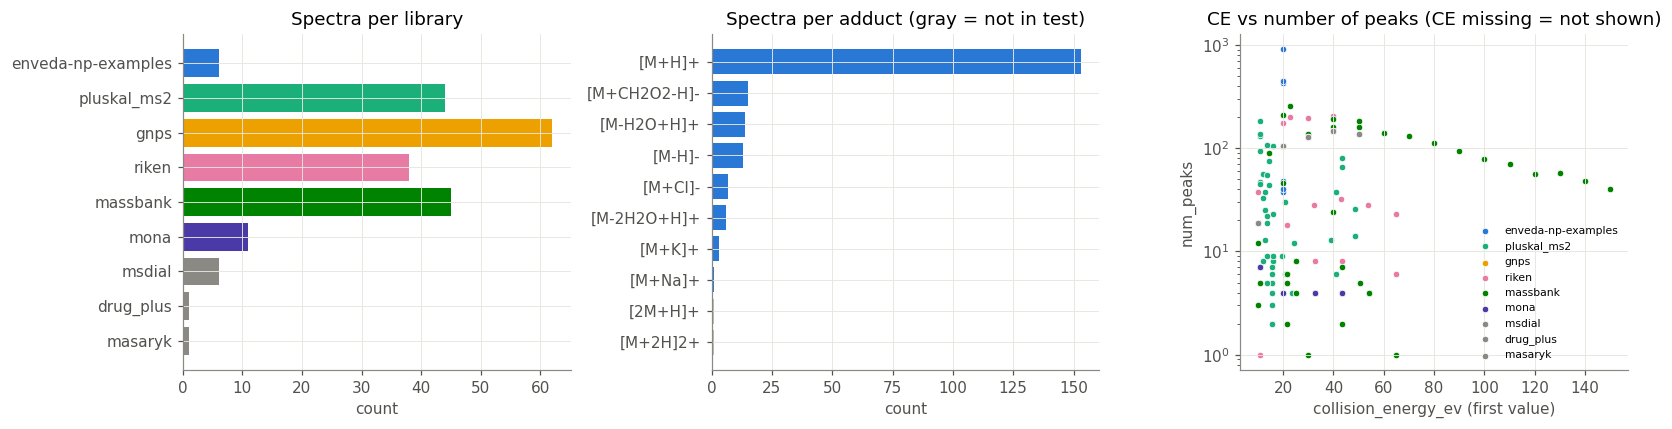

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

lib_counts = mol["ingest_lib"].value_counts().reindex([l for l in LIB_ORDER if l in set(mol["ingest_lib"])])
axes[0].barh(lib_counts.index[::-1], lib_counts.values[::-1], color=[LIB_COLOR[l] for l in lib_counts.index[::-1]])
axes[0].set_title("Spectra per library")
axes[0].set_xlabel("count")

add_counts = mol["adduct"].value_counts()
axes[1].barh(add_counts.index[::-1], add_counts.values[::-1],
             color=["#2a78d6" if a in TEST_ADDUCTS else "#bdbbb4" for a in add_counts.index[::-1]])
axes[1].set_title("Spectra per adduct (gray = not in test)")
axes[1].set_xlabel("count")

for lib, g in mol.groupby("ingest_lib", sort=False):
    axes[2].scatter(g["ce_first"], g["num_peaks"], s=18, color=LIB_COLOR[lib], label=lib,
                    edgecolor="white", linewidth=0.5)
axes[2].set_xlabel("collision_energy_ev (first value)")
axes[2].set_ylabel("num_peaks")
axes[2].set_yscale("log")
axes[2].set_title("CE vs number of peaks (CE missing = not shown)")
axes[2].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

## 5. 全スペクトルの俯瞰(ヒートマップ)

1分子に数百スペクトルあるため、まず全体を1枚で見る。
各行が1スペクトル(ライブラリ→アダクト→CE順)、横軸は m/z を 1 Da ビンで集約した正規化強度。
白い縦線はモノアイソトピック質量。左端の色帯はライブラリを示す。

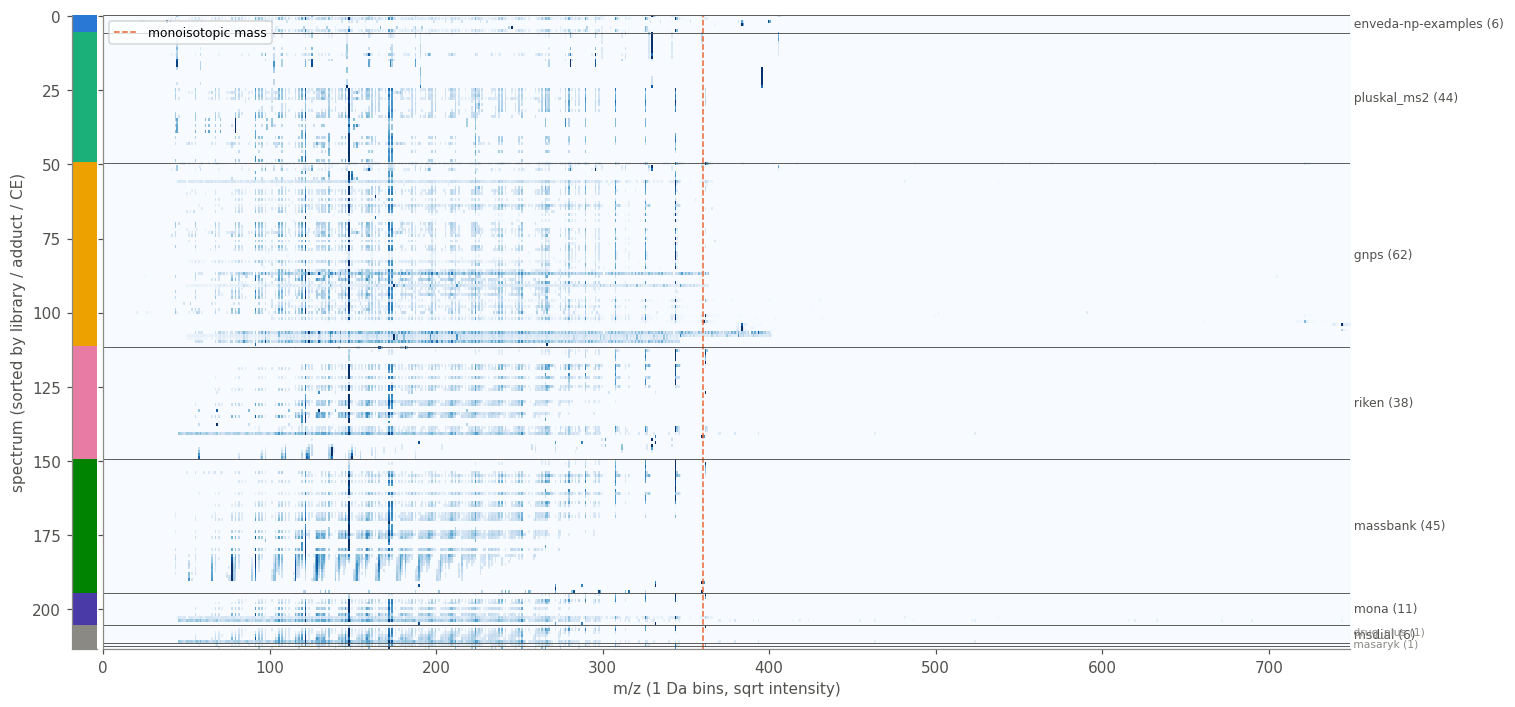

In [10]:
BIN = 1.0
mz_max = float(mol["precursor_mz"].max()) + 5
edges = np.arange(0, mz_max + BIN, BIN)
mat = np.zeros((len(mol), len(edges) - 1))
for i, (mzs, ints) in enumerate(zip(mol["ms2_mzs"], mol["ms2_normalized_intensities"])):
    h, _ = np.histogram(np.asarray(mzs), bins=edges, weights=np.asarray(ints))
    mat[i] = np.minimum(h, 1.0)

fig, (ax_lib, ax) = plt.subplots(1, 2, figsize=(15, max(4, len(mol) * 0.035)),
                                 gridspec_kw={"width_ratios": [0.02, 1], "wspace": 0.01}, sharey=True)
lib_idx = mol["ingest_lib"].map({l: i for i, l in enumerate(LIB_ORDER)}).to_numpy()[:, None]
from matplotlib.colors import ListedColormap
ax_lib.imshow(lib_idx, aspect="auto", cmap=ListedColormap([LIB_COLOR[l] for l in LIB_ORDER]),
              vmin=0, vmax=len(LIB_ORDER) - 1, interpolation="nearest")
ax_lib.set_xticks([])
ax_lib.grid(False)
ax_lib.set_ylabel("spectrum (sorted by library / adduct / CE)")

ax.imshow(np.sqrt(mat), aspect="auto", cmap="Blues", extent=[0, edges[-1], len(mol) - 0.5, -0.5],
          interpolation="nearest")
ax.axvline(Descriptors.ExactMolWt(m), color="#eb6834", lw=1, ls="--", label="monoisotopic mass")
ax.grid(False)
ax.set_xlabel("m/z (1 Da bins, sqrt intensity)")
ax.legend(loc="upper left", fontsize=8)

# ライブラリの境界とラベル
bounds = mol.groupby("ingest_lib", sort=False).indices
small = []
for lib, idx in bounds.items():
    ax.axhline(idx.min() - 0.5, color="#52514e", lw=0.6)
    if len(idx) >= 3:
        ax.text(edges[-1], idx.mean(), f" {lib} ({len(idx)})", va="center", fontsize=8, color="#52514e")
    else:
        small.append(f"{lib} ({len(idx)})")
if small:
    ax.text(edges[-1], len(mol) - 0.5, " " + "\n ".join(small), va="bottom", fontsize=7, color="#8a8984")
plt.show()

## 6. 代表スペクトル

`enveda-np-examples` は全スペクトルを描く。他のライブラリは、この分子で最も多いアダクトのうち
CEが中央値に最も近いスペクトルを1本ずつ選ぶ(最大 `MAX_PANELS` 枚)。縦の破線はプリカーサー m/z。

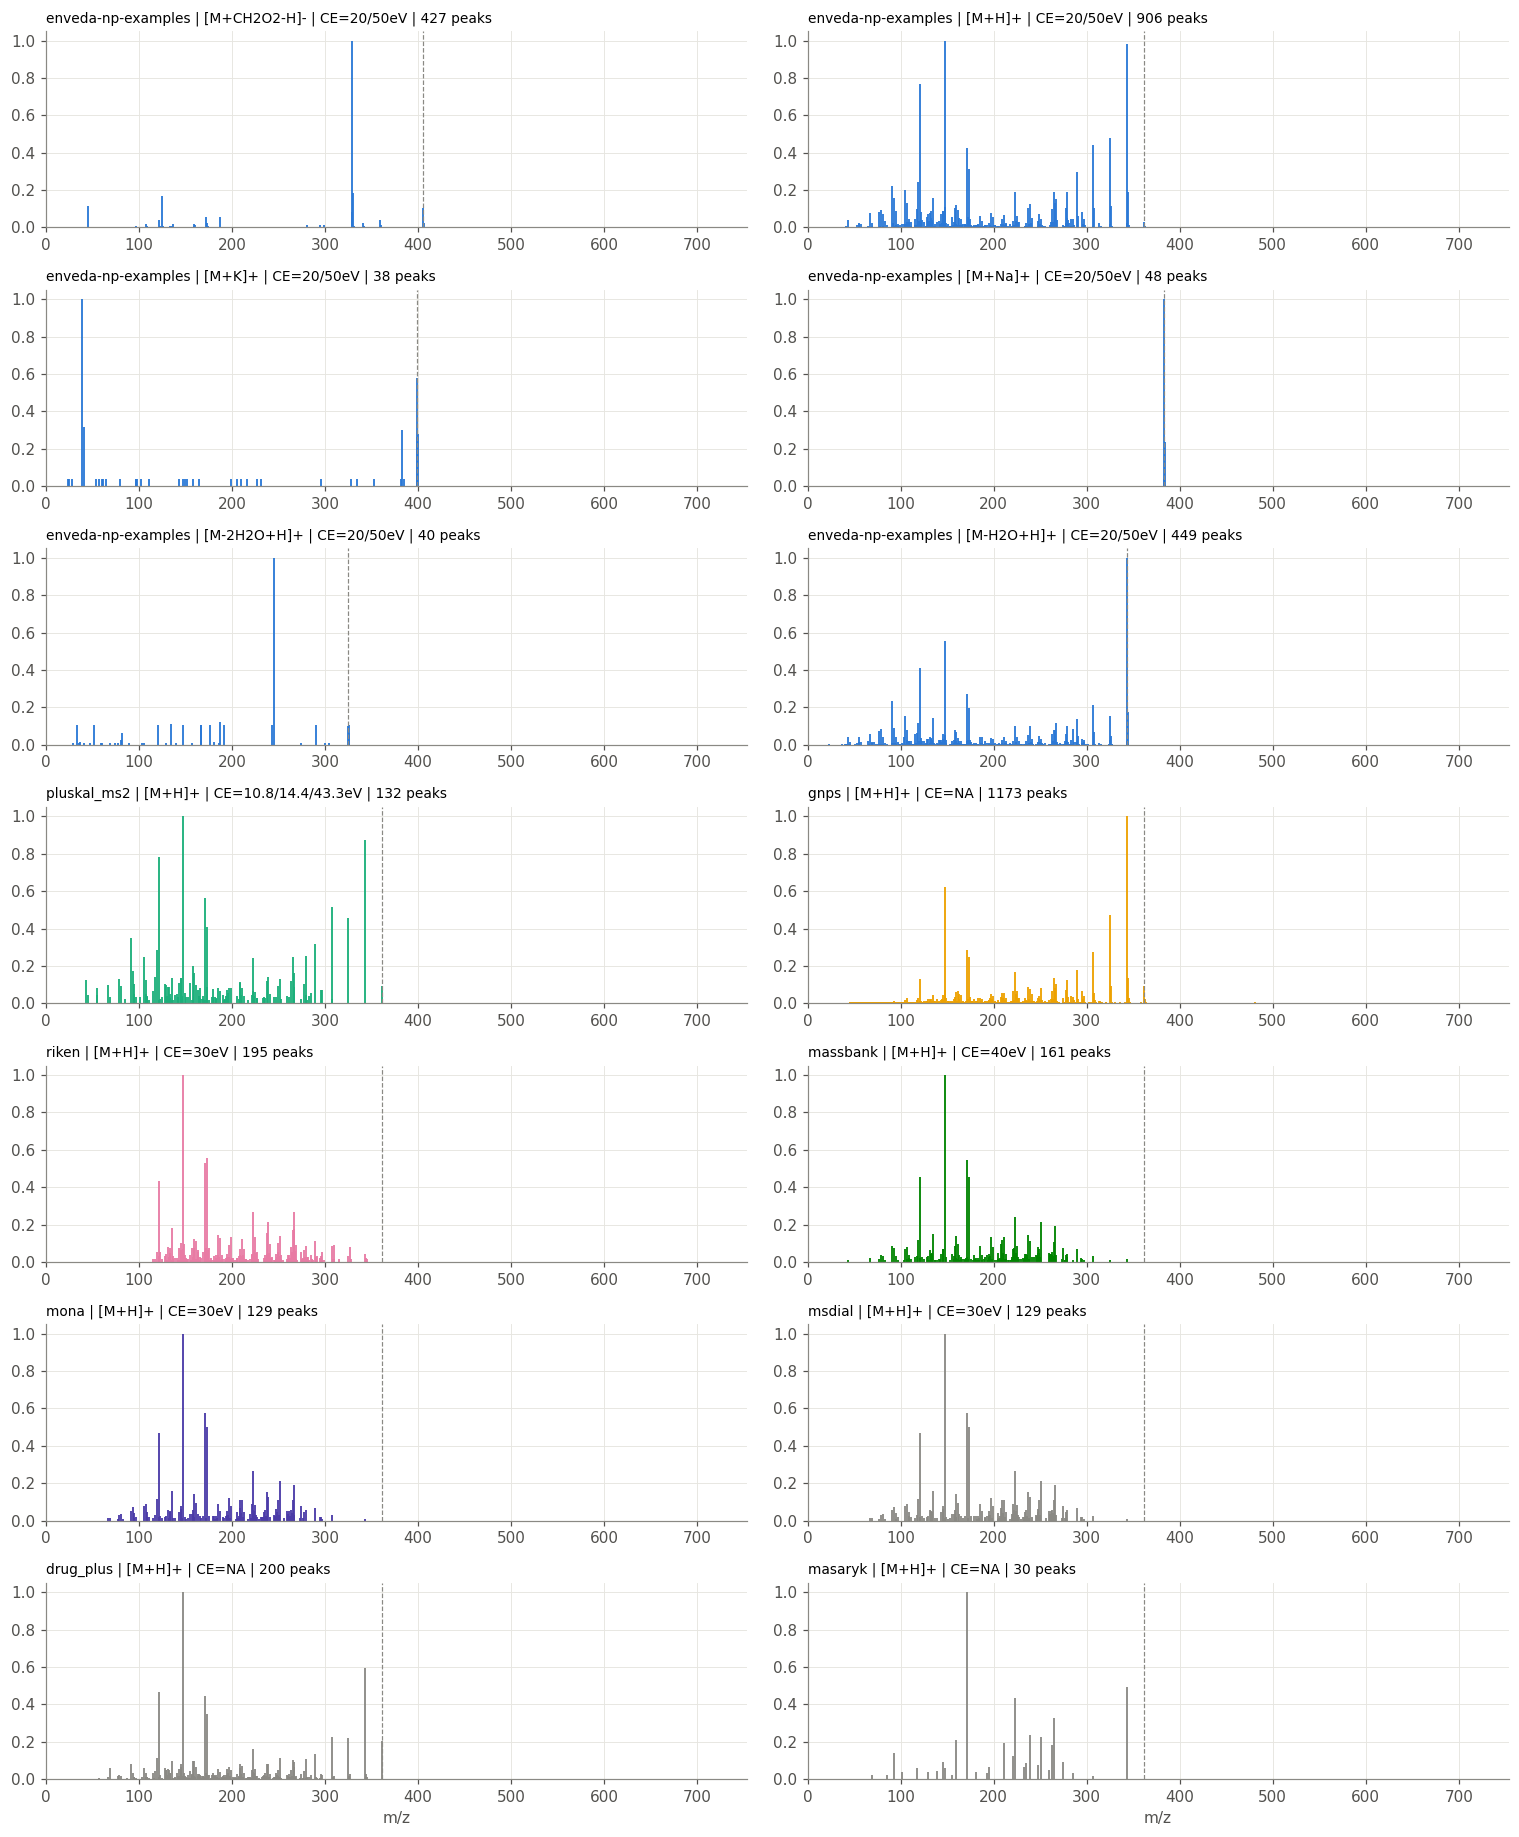

In [11]:
MAX_PANELS = 16


def pick_representatives(df):
    rows = list(df.index[df["ingest_lib"] == "enveda-np-examples"])
    main_adduct = df["adduct"].mode()[0]
    for lib, g in df[df["ingest_lib"] != "enveda-np-examples"].groupby("ingest_lib", sort=False):
        g = g[g["adduct"] == main_adduct] if (g["adduct"] == main_adduct).any() else g
        ce = g["ce_first"]
        rows.append((ce - ce.median()).abs().idxmin() if ce.notna().any() else g["num_peaks"].idxmax())
    return df.loc[rows]


def ce_label(x):
    return "CE=NA" if x is None or len(x) == 0 else "CE=" + "/".join(f"{v:g}" for v in x) + "eV"


def plot_spectrum(ax, row, color, sign=1):
    mzs = np.asarray(row["ms2_mzs"])
    ints = np.asarray(row["ms2_normalized_intensities"]) * sign
    ax.vlines(mzs, 0, ints, color=color, lw=1.2)
    ax.axvline(row["precursor_mz"], color="#8a8984", lw=0.8, ls="--")
    ax.axhline(0, color="#52514e", lw=0.6)


reps = pick_representatives(mol).head(MAX_PANELS)

ncol = 2
nrow = int(np.ceil(len(reps) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 2.4 * nrow), squeeze=False)
xmax = float(mol["precursor_mz"].max()) + 10
for ax, (_, row) in zip(axes.flat, reps.iterrows()):
    plot_spectrum(ax, row, LIB_COLOR[row["ingest_lib"]])
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{row['ingest_lib']} | {row['adduct']} | {ce_label(row['collision_energy_ev'])} | "
                 f"{row['num_peaks']} peaks", fontsize=9, loc="left")
for ax in axes.flat[len(reps):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("m/z")
plt.tight_layout()
plt.show()

## 7. ミラープロット: enveda-np-examples と他ライブラリの比較

テストに最も近い `enveda-np-examples` のスペクトル(上)と、同じアダクトで他ライブラリのスペクトル(下)を比べる。
下側は各ライブラリからコサイン類似度が最も高いものを選ぶ。類似度は 0.01 Da 許容の簡易マッチング(sqrt強度)。

,ingest_lib,adduct,collision_energy_ev,num_peaks,cosine
25,pluskal_ms2,[M+H]+,"[10.8, 14.4, 43.3]",132,0.866
59,gnps,[M+H]+,None,148,0.867
140,riken,[M+H]+,None,155,0.853
169,massbank,[M+H]+,[40.0],191,0.843
197,mona,[M+H]+,[20.0],106,0.789
207,msdial,[M+H]+,[20.0],106,0.788
212,drug_plus,[M+H]+,None,200,0.886
213,masaryk,[M+H]+,None,30,0.455


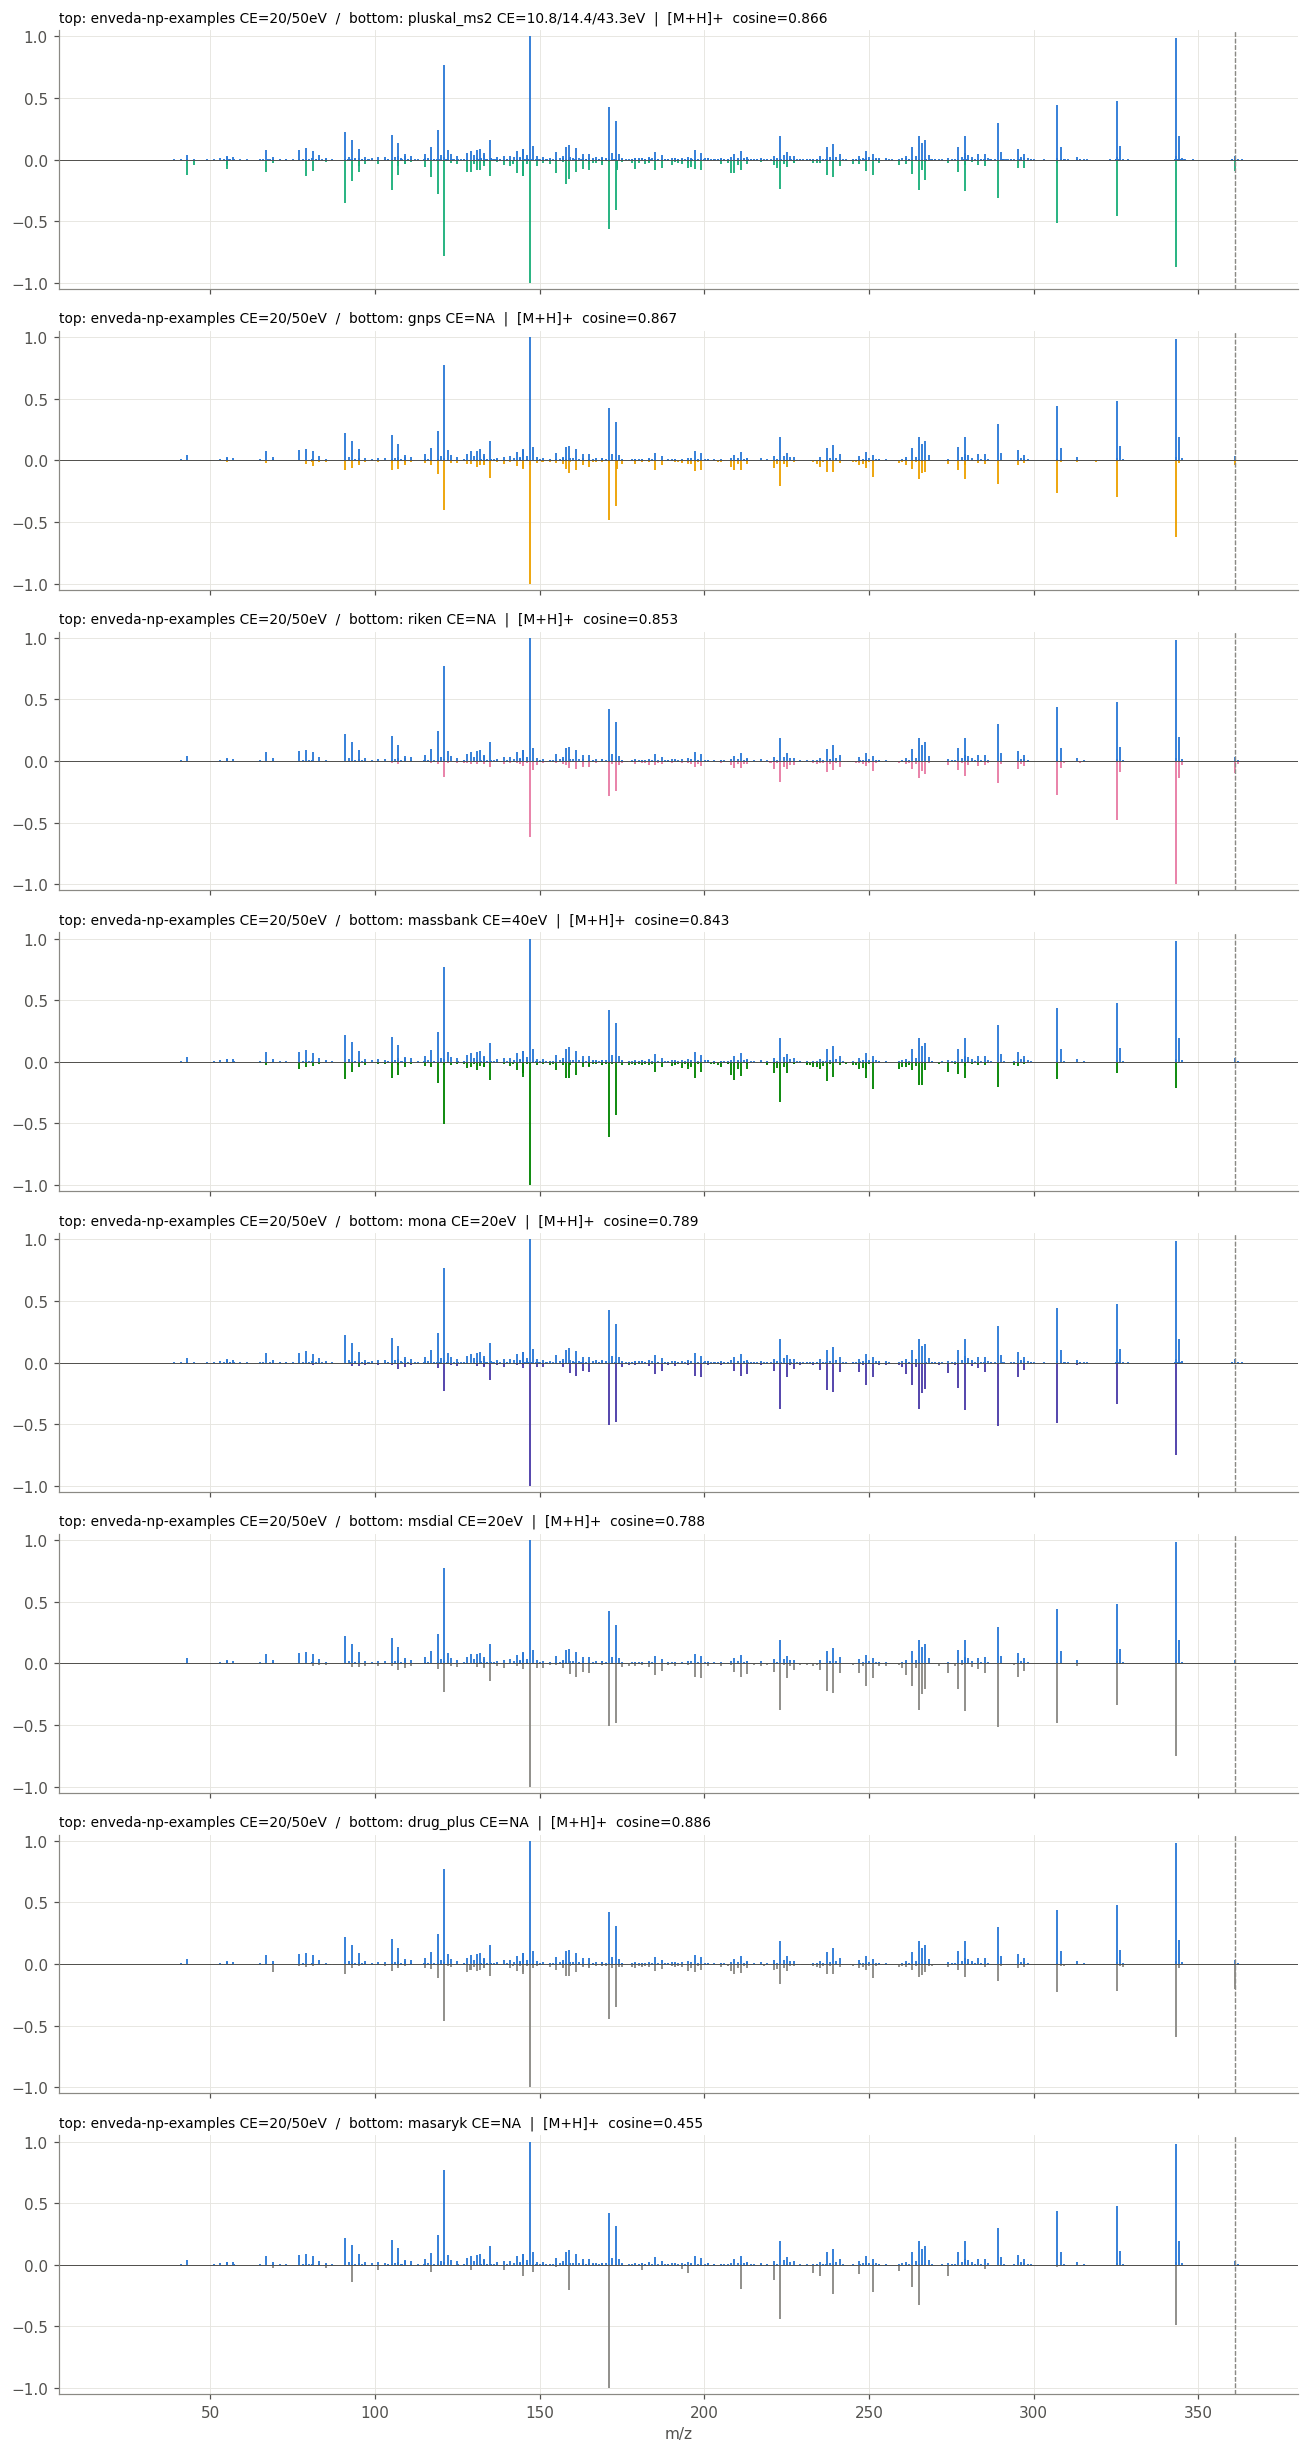

In [12]:
def cosine(mz1, i1, mz2, i2, tol=0.01):
    mz1, mz2 = np.asarray(mz1), np.asarray(mz2)
    a, b = np.sqrt(np.asarray(i1)), np.sqrt(np.asarray(i2))
    j = np.searchsorted(mz2, mz1)
    score, used = 0.0, set()
    for k in np.argsort(-a):
        best = None
        for jj in (j[k] - 1, j[k]):
            if 0 <= jj < len(mz2) and jj not in used and abs(mz2[jj] - mz1[k]) <= tol:
                if best is None or b[jj] > b[best]:
                    best = jj
        if best is not None:
            used.add(best)
            score += a[k] * b[best]
    return score / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)


query = mol[mol["ingest_lib"] == "enveda-np-examples"]
query = query[query["adduct"].isin(mol.loc[mol["ingest_lib"] != "enveda-np-examples", "adduct"])]
q = query.loc[query["num_peaks"].idxmax()]
others = mol[(mol["ingest_lib"] != "enveda-np-examples") & (mol["adduct"] == q["adduct"])].copy()
others["cosine"] = [cosine(q["ms2_mzs"], q["ms2_normalized_intensities"], r["ms2_mzs"], r["ms2_normalized_intensities"])
                    for _, r in others.iterrows()]
best = others.loc[others.groupby("ingest_lib")["cosine"].idxmax()].sort_values("lib_rank")
display(best[["ingest_lib", "adduct", "collision_energy_ev", "num_peaks", "cosine"]].round(3))

fig, axes = plt.subplots(len(best), 1, figsize=(12, 2.8 * len(best)), squeeze=False, sharex=True)
for ax, (_, r) in zip(axes[:, 0], best.iterrows()):
    plot_spectrum(ax, q, LIB_COLOR["enveda-np-examples"], sign=1)
    plot_spectrum(ax, r, LIB_COLOR[r["ingest_lib"]], sign=-1)
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(f"top: enveda-np-examples {ce_label(q['collision_energy_ev'])}  /  "
                 f"bottom: {r['ingest_lib']} {ce_label(r['collision_energy_ev'])}  |  "
                 f"{q['adduct']}  cosine={r['cosine']:.3f}", fontsize=9, loc="left")
axes[-1, 0].set_xlabel("m/z")
plt.tight_layout()
plt.show()

## メモ

- 同じ分子でもライブラリ・装置・CEによってピーク数やフラグメントパターンが大きく異なる
- `collision_energy_ev` が欠損するライブラリ(gnps など)がある
- `TARGET_INCHIKEY14` を変えて他の分子も確認する